# 13. Política de mantenimiento y evaluación final

Desarrollamos el **paso 3.4**. Elegimos modelo y umbral con los costos de validación; comparamos contra operar hasta la falla y un calendario por componente. Después fijamos las decisiones y evaluamos **solo el modelo elegido** una vez en prueba.

Los costos son 15 000 por falla no anticipada, 3 000 por intervención acertada y 600 por falsa alarma. Incluimos sensibilidad a la razón falla/falsa alarma. Los CSV originales y preparados permanecen intactos. Tablas, resultados y gráficas se conservan en este notebook.

## 1. Qué contamos y qué suponemos

- La unidad es una **falla de componente**: dos componentes que fallan en la misma máquina y hora cuentan como dos. Esto difiere del agrupamiento binario máquina-hora del notebook 09.
- La política predictiva confirma una alerta en la tercera hora consecutiva sobre el umbral. Emite **una acción por racha**; si continúa alta, no vuelve a cobrar una intervención cada hora. Un hueco o una hora baja reinicia la racha.
- En la confirmación se propone el componente con mayor puntuación entre comp1–comp4. La cabeza binaria decide cuándo alertar y la multiclase cuál revisar. La clase “ninguno” no es una orden de reemplazo. Esta regla se fija antes de mirar los costos o prueba.
- Una acción acierta si la **siguiente falla de ese componente y máquina** está en `(t, t+24 h]`. Se acredita una sola acción por falla. Acciones adicionales para la misma falla cuestan 600 y no vuelven a evitarla; una intervención al mismo tiempo que la falla llega tarde.
- Cada falla no acreditada cuesta 15 000. No se suman además 15 000 a una falla anticipada: en ese caso se cobran 3 000. Una acción al componente equivocado cuesta 600 y la falla del otro sigue sin anticiparse.

La comparación es una **reproducción retrospectiva bajo supuestos**, no una simulación física de una planta intervenida. Conservamos sensores, fallas y mantenimientos históricos incluso después de una acción simulada. No conocemos cómo cambiarían; no afirmamos ahorro real ni fallas efectivamente evitadas. Tampoco modelamos capacidad de técnicos, repuestos o duración del paro.

Usamos todas las fallas del periodo y exactamente las horas disponibles en cada CSV preparado. Sus bordes no ofrecen 24 horas completas de alertas para algunas fallas; las contamos también y mostramos cuántas son. Las tres políticas comparten esas oportunidades, sin incorporar horas de otros conjuntos para decidir.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import subprocess
import tempfile
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nbformat
from IPython.display import display
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix, brier_score_loss)

# Encontrar los datos desde la raíz del proyecto o desde Modelación.
actual = Path.cwd()
ruta_repo = actual if (actual / "Datos").is_dir() else actual.parent
assert (ruta_repo / "Datos").is_dir()
for carpeta in ["Preprocesamiento", "Modelación"]:
    ruta = str(ruta_repo / carpeta)
    if ruta not in sys.path:
        sys.path.insert(0, ruta)

claves_13 = ["machineID", "datetime"]
componentes_13 = ["comp1", "comp2", "comp3", "comp4"]
clases_13 = ["ninguno"] + componentes_13
costos_13 = {"falla": 15000, "acierto": 3000, "falsa_alarma": 600}
columnas_reloj_13 = [comp + "_horas_desde_reemplazo" for comp in componentes_13]
validacion_13 = pd.read_csv(ruta_repo / "Datos/Datos_preparados/validación.csv", parse_dates=["datetime"])
validacion_13 = validacion_13.sort_values(claves_13).reset_index(drop=True)
assert len(validacion_13) == 144000
assert validacion_13.datetime.between("2015-09-01", "2015-11-01", inclusive="left").all()
assert (validacion_13.datetime + pd.Timedelta(hours=24) < pd.Timestamp("2015-11-01")).all()

# La lectura de prueba está únicamente después del acta de decisiones.
pd.set_option("display.max_columns", 18)
pd.set_option("display.precision", 5)
plt.rcParams["figure.dpi"] = 150
display(pd.DataFrame({"concepto": list(costos_13), "costo": list(costos_13.values())}))

,concepto,costo
0,falla,15000
1,acierto,3000
2,falsa_alarma,600


## 2. Recuperar tres candidatos ya definidos

Comparamos **XGBoost del 05**, **CNN-LSTM ponderada de 24 horas del 08** y **Transformer del 10**, sin otra búsqueda de arquitectura. XGBoost fue la mejor línea base por AP y CNN-LSTM la mejor red de la segunda fase por AP; el Transformer aporta la alternativa avanzada. No atribuimos a esta comparación una búsqueda exhaustiva de todos los modelos del proyecto.

Si las redes siguen disponibles en el mismo kernel se reutilizan. Si no, se reconstruyen solamente sus ajustes originales, con sus semillas y selección de época en validación. En una sesión nueva esto puede tardar varios minutos. Los modelos ajustan pesos solo con entrenamiento; no se reentrenan con validación ni prueba.

Usamos las puntuaciones deterministas originales para mantener la comparación del 09–10. La calibración del 11 y MC Dropout estudiaron el Transformer; no se trasladan automáticamente a los otros modelos. Aquí **no suponemos que una probabilidad sea un riesgo perfectamente calibrado**: buscamos el umbral empíricamente por costos de episodios. Una temperatura binaria positiva conserva el orden de las puntuaciones, pero una cuadrícula numérica finita puede producir puntos distintos.

XGBoost se ejecuta en un proceso separado para evitar el conflicto nativo con PyTorch observado en macOS. Sus objetos pasan por una carpeta temporal fuera del repositorio, que se elimina al terminar. No se exportan modelos permanentes, figuras ni CSV de resultados.

In [2]:
# Guardar temporalmente el XGBoost entrenado permite predecir prueba después de fijar la política.
# El mismo objeto se reutiliza: no se vuelve a ajustar ni se cambia su configuración.
codigo_xgb_13 = r"""
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import nbformat
import joblib
from threadpoolctl import threadpool_limits
os.chdir(sys.argv[1])
modo, carpeta = sys.argv[2], Path(sys.argv[3])
if modo == "ajustar":
    fuente = nbformat.read(Path("Modelación") / "05_línea_base_clásica.ipynb", as_version=4)
    espacio = {}
    for numero in [2, 4, 7, 9]:
        exec(compile(fuente.cells[numero].source, "definiciones_05", "exec"), espacio)
    binaria = espacio["modelos_binarios"]["XGBoost"]
    multi = espacio["modelos_multiclase"]["XGBoost"]
    with threadpool_limits(limits=espacio["HILOS"]):
        binaria.fit(espacio["X_train"], espacio["y_train_bin"])
        multi.fit(espacio["X_train"], espacio["y_train_multi"],
                  modelo__sample_weight=espacio["pesos_multiclase"])
    columnas = espacio["columnas_entrada"]
    tabla = espacio["validacion"]
    joblib.dump({"binaria": binaria, "multi": multi, "columnas": columnas}, carpeta / "xgb.joblib")
else:
    guardado = joblib.load(carpeta / "xgb.joblib")
    binaria, multi, columnas = guardado["binaria"], guardado["multi"], guardado["columnas"]
    tabla = pd.read_csv(Path("Datos/Datos_preparados/prueba.csv"), parse_dates=["datetime"])
orden = tabla.sort_values(["machineID", "datetime"]).index.to_numpy()
entradas = tabla.iloc[orden][columnas]
assert np.array_equal(multi.named_steps["modelo"].classes_, np.arange(5))
np.savez_compressed(carpeta / (modo + ".npz"),
    binaria=binaria.predict_proba(entradas)[:, 1], multiclase=multi.predict_proba(entradas),
    ids=tabla.iloc[orden]["machineID"].to_numpy(), horas=tabla.iloc[orden]["datetime"].to_numpy())
"""

def ejecutar_xgb_13(modo):
    """Ajustar en entrenamiento o predecir con los objetos ya ajustados, en otro proceso."""
    proceso = subprocess.run([sys.executable, "-c", codigo_xgb_13, str(ruta_repo), modo,
                              temporal_xgb_13.name], capture_output=True, text=True)
    if proceso.returncode != 0:
        raise RuntimeError("XGBoost no terminó correctamente: " + proceso.stderr[-1500:])
    with np.load(Path(temporal_xgb_13.name) / (modo + ".npz")) as archivo:
        return {nombre: archivo[nombre].copy() for nombre in archivo.files}


temporal_xgb_13 = tempfile.TemporaryDirectory()
xgb_validacion_13 = ejecutar_xgb_13("ajustar")
assert np.array_equal(xgb_validacion_13["ids"], validacion_13.machineID)
assert np.array_equal(xgb_validacion_13["horas"], validacion_13.datetime.to_numpy())
predicciones_validacion_13 = {"XGBoost": {k: xgb_validacion_13[k] for k in ["binaria", "multiclase"]}}
print("XGBoost original ajustado solo con entrenamiento; validación alineada.")

# Reutilizar la preparación y el CNN-LSTM del 08 o reconstruir solo ese ensayo.
import torch
from preparar_secuencias import preparar_secuencias
from entrenamiento_secuencial import entrenar_ensayo, indices_comunes
from torch.utils.data import DataLoader

torch.set_num_threads(1)
if "preparacion_10" in globals():
    preparacion_13 = preparacion_10
elif "preparacion" in globals():
    preparacion_13 = preparacion
else:
    preparacion_13 = preparar_secuencias(ruta_repo)
clave_cnn_13 = ("CNN-LSTM", 24, "ponderada")
if "resultados" in globals() and clave_cnn_13 in resultados:
    cnn_13 = resultados[clave_cnn_13]
else:
    configuracion_cnn_13 = {"semilla": 42, "hilos": 1, "batch_size": 512, "max_epocas": 6,
        "paciencia": 2, "min_delta": .0001, "learning_rate": .001, "weight_decay": .0001, "dropout": .10}
    cnn_13 = entrenar_ensayo(preparacion_13, indices_comunes(preparacion_13),
                            *clave_cnn_13, configuracion_cnn_13)

# El 10 conserva su arquitectura y su función de entrenamiento en el propio notebook.
# Las definiciones se ejecutan en un espacio separado para no sobrescribir estas variables.
if "resultado_transformer" in globals():
    transformer_13 = resultado_transformer
else:
    fuente_10_13 = nbformat.read(ruta_repo / "Modelación/10_transformer.ipynb", as_version=4)
    espacio_10_13 = {}
    for numero in [3, 6, 8, 15]:
        exec(compile(fuente_10_13.cells[numero].source, "ajuste_original_10", "exec"), espacio_10_13)
    transformer_13 = espacio_10_13["resultado_transformer"]

anclas_validacion_13 = preparacion_13["anclas"][24]["validación"].reset_index(drop=True)
orden_13 = anclas_validacion_13.sort_values(claves_13).index.to_numpy()
pd.testing.assert_frame_equal(anclas_validacion_13.iloc[orden_13][claves_13].reset_index(drop=True),
                              validacion_13[claves_13], check_dtype=False)
for nombre, resultado in [("CNN-LSTM", cnn_13), ("Transformer", transformer_13)]:
    pred = resultado["predicciones"]
    assert np.array_equal(pred["y_binaria"][orden_13], validacion_13.etiqueta_binaria)
    codigos = validacion_13.etiqueta_multiclase.map(dict(zip(clases_13, range(5))))
    assert np.array_equal(pred["y_multiclase"][orden_13], codigos)
    predicciones_validacion_13[nombre] = {"binaria": pred["prob_binaria"][orden_13],
                                       "multiclase": pred["prob_multiclase"][orden_13]}
for pred in predicciones_validacion_13.values():
    assert np.isfinite(pred["binaria"]).all() and np.isfinite(pred["multiclase"]).all()
    assert np.allclose(pred["multiclase"].sum(axis=1), 1, atol=1e-5)
print("Tres candidatos alineados en las mismas 144 000 horas; prueba sigue sin abrirse.")

XGBoost original ajustado solo con entrenamiento; validación alineada.
INICIO CNN-LSTM | L=24 | ponderada
CNN-LSTM | L=24 | ponderada época 1 lotes 300 / 1101
CNN-LSTM | L=24 | ponderada época 1 lotes 600 / 1101
CNN-LSTM | L=24 | ponderada época 1 lotes 900 / 1101
CNN-LSTM | L=24 | ponderada FIN época 1 PR-AUC 0.548893 segundos 97.0
CNN-LSTM | L=24 | ponderada época 2 lotes 300 / 1101
CNN-LSTM | L=24 | ponderada época 2 lotes 600 / 1101
CNN-LSTM | L=24 | ponderada época 2 lotes 900 / 1101
CNN-LSTM | L=24 | ponderada FIN época 2 PR-AUC 0.946999 segundos 98.1
CNN-LSTM | L=24 | ponderada época 3 lotes 300 / 1101
CNN-LSTM | L=24 | ponderada época 3 lotes 600 / 1101
CNN-LSTM | L=24 | ponderada época 3 lotes 900 / 1101
CNN-LSTM | L=24 | ponderada FIN época 3 PR-AUC 0.984508 segundos 95.6
CNN-LSTM | L=24 | ponderada época 4 lotes 300 / 1101
CNN-LSTM | L=24 | ponderada época 4 lotes 600 / 1101
CNN-LSTM | L=24 | ponderada época 4 lotes 900 / 1101
CNN-LSTM | L=24 | ponderada FIN época 4 PR-AUC 0

,conjunto,ejemplos,horas_por_ventana,canales
0,entrenamiento,563500,24,13
1,validación,144000,24,13


,parámetro,valor
0,semilla,42.0000
1,hilos,1.0000
2,L,24.0000
3,dimension,32.0000
4,cabezas,4.0000
5,capas,2.0000
6,internas,64.0000
7,dropout,0.1000
8,batch_size,512.0000
9,max_epocas,6.0000


Parámetros entrenables: 19046
TransformerMantenimiento(
  (proyectar_sensores): Linear(in_features=13, out_features=32, bias=True)
  (posiciones): CodificacionPosicional()
  (embedding_modelo): Embedding(5, 32, padding_idx=0)
  (proyectar_edad): Linear(in_features=1, out_features=32, bias=True)
  (dropout_entrada): Dropout(p=0.1, inplace=False)
  (bloques): ModuleList(
    (0-1): 2 x TransformerEncoderLayer(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
      )
      (linear1): Linear(in_features=32, out_features=64, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (linear2): Linear(in_features=64, out_features=32, bias=True)
      (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout1): Dropout(p=0.1, inplace=False)
      (dropout2): Dropout(p=0.1, inplace=False)
    )
  

,epoca,PR_AUC_validacion,segundos,train_total,val_total,train_binaria,val_binaria,train_multiclase,val_multiclase
0,1,0.896957,145.096044,0.205965,0.051569,0.175999,0.051994,0.250914,0.050932
1,2,0.995518,159.958217,0.043319,0.014062,0.039883,0.007921,0.048475,0.023274
2,3,0.992549,154.759829,0.015949,0.010642,0.014527,0.006612,0.018083,0.016688
3,4,0.992861,149.953539,0.012172,0.011404,0.011757,0.005622,0.012795,0.020077


Épocas ejecutadas: 4
Mejor época conservada: 2
Tres candidatos alineados en las mismas 144 000 horas; prueba sigue sin abrirse.


## 3. Funciones de acciones y costos

El costo total se calcula como:

`3 000 × fallas anticipadas + 600 × acciones sin un nuevo acierto + 15 000 × fallas no anticipadas`.

Dividirlo entre las horas disponibles y multiplicarlo por 1 000 da el costo por 1 000 horas-máquina observadas. Todas las políticas del periodo usan el mismo denominador y las mismas fallas.

La información futura se consulta **solo para puntuar** una acción ya decidida. La decisión predictiva usa sus puntuaciones actuales y anteriores; el calendario usa el tiempo desde reemplazos estrictamente anteriores, calculado por el pipeline. Las funciones separan decisión y evaluación para no usar la próxima falla al decidir.

In [3]:
def fallas_periodo_13(inicio, fin):
    """Leer los eventos para evaluar después; no se usan como variables del modelo."""
    tabla = pd.read_csv(ruta_repo / "Datos/PdM_failures.csv", parse_dates=["datetime"])
    tabla = tabla.loc[tabla.datetime.between(inicio, fin, inclusive="left")]
    tabla = tabla.rename(columns={"failure": "componente"})
    tabla = tabla[["machineID", "datetime", "componente"]].drop_duplicates().sort_values(
        ["machineID", "datetime", "componente"]).reset_index(drop=True)
    tabla["evento"] = np.arange(len(tabla))
    return tabla


def preparar_evaluacion_13(tabla, eventos):
    """Precalcular correspondencias futuras únicamente para puntuar las decisiones."""
    horas = tabla.datetime.to_numpy(dtype="datetime64[ns]")
    ids = tabla.machineID.to_numpy()
    siguiente = np.full((len(tabla), 4), -1, dtype=int)
    for (maquina, componente), grupo in eventos.groupby(["machineID", "componente"]):
        posiciones = np.flatnonzero(ids == maquina)
        fechas = grupo.datetime.to_numpy(dtype="datetime64[ns]")
        busqueda = np.searchsorted(fechas, horas[posiciones], side="right")
        candidatas = np.minimum(busqueda, len(fechas) - 1)
        distancia = (fechas[candidatas] - horas[posiciones]) / np.timedelta64(1, "h")
        acierta = (busqueda < len(fechas)) & (distancia > 0) & (distancia <= 24)
        siguiente[posiciones[acierta], componentes_13.index(componente)] = grupo.evento.to_numpy()[candidatas[acierta]]

    # Verificar continuidad de la ventana usada para confirmar tres horas.
    continuidad = np.zeros(len(tabla), dtype=bool)
    continuidad[1:] = ((ids[1:] == ids[:-1]) &
                       ((horas[1:] - horas[:-1]) == np.timedelta64(1, "h")))
    frontera = 0
    por_maquina = {m: pd.DatetimeIndex(g.datetime) for m, g in tabla.groupby("machineID")}
    for evento in eventos.itertuples(index=False):
        requeridas = pd.date_range(evento.datetime - pd.Timedelta(hours=24), periods=24, freq="h")
        frontera += int(not requeridas.isin(por_maquina[evento.machineID]).all())
    return {"siguiente": siguiente, "continuidad": continuidad, "eventos": len(eventos),
            "horas": len(tabla), "fallas_con_borde": frontera}


def confirmar_13(probabilidades, umbral, continuidad):
    """Devolver las filas donde se completa por primera vez una racha de tres horas."""
    alto = np.asarray(probabilidades) >= umbral
    tres = np.zeros(len(alto), dtype=bool)
    tres[2:] = (alto[2:] & alto[1:-1] & alto[:-2] & continuidad[2:] & continuidad[1:-1])
    anterior = np.r_[False, tres[:-1]] & continuidad
    return np.flatnonzero(tres & ~anterior)


def contar_costos_13(filas, componentes, evaluacion, costos):
    """Acreditar como máximo una intervención por falla y cobrar las demás acciones."""
    filas = np.asarray(filas, dtype=int)
    componentes = np.asarray(componentes, dtype=int)
    eventos = evaluacion["siguiente"][filas, componentes]
    anticipadas = len(np.unique(eventos[eventos >= 0]))
    falsas = len(filas) - anticipadas
    omitidas = evaluacion["eventos"] - anticipadas
    total = costos["acierto"] * anticipadas + costos["falsa_alarma"] * falsas + costos["falla"] * omitidas
    return {"acciones": len(filas), "anticipadas": anticipadas, "sin_acierto_nuevo": falsas,
            "no_anticipadas": omitidas, "costo_total": total,
            "costo_por_1000_h": total / evaluacion["horas"] * 1000}


def acciones_calendario_13(tabla, componente, intervalo):
    """Revisar un componente por edad desde el último reemplazo conocido o acción virtual."""
    if np.isinf(intervalo):
        return np.array([], dtype=int)
    columna = componentes_13[componente] + "_horas_desde_reemplazo"
    acciones = []
    for maquina, grupo in tabla.groupby("machineID", sort=True):
        ultima_virtual = None
        for fila, hora, edad_real in zip(grupo.index, grupo.datetime, grupo[columna]):

            # Ambos relojes usan solo el pasado: el menor incorpora el reemplazo más reciente.
            edad_virtual = np.inf if ultima_virtual is None else (hora - ultima_virtual).total_seconds() / 3600
            if pd.notna(edad_real) and min(edad_real, edad_virtual) >= intervalo:
                acciones.append(fila)
                ultima_virtual = hora
    return np.array(acciones, dtype=int)


# Ejemplo controlado: una racha, una falla futura, duplicado y componente equivocado.
ejemplo_13 = pd.DataFrame({"machineID": [1] * 6,
    "datetime": pd.date_range("2015-09-05 08:00", periods=6, freq="h")})
eventos_ejemplo_13 = pd.DataFrame({"machineID": [1], "datetime": [pd.Timestamp("2015-09-05 13:00")],
                                  "componente": ["comp1"], "evento": [0]})
evaluacion_ejemplo_13 = preparar_evaluacion_13(ejemplo_13, eventos_ejemplo_13)
filas = confirmar_13(np.array([.9, .9, .9, .9, .1, .9]), .8, evaluacion_ejemplo_13["continuidad"])
assert filas.tolist() == [2]
assert contar_costos_13(filas, [0], evaluacion_ejemplo_13, costos_13)["costo_total"] == 3000
assert contar_costos_13([2, 3], [0, 0], evaluacion_ejemplo_13, costos_13)["costo_total"] == 3600
assert contar_costos_13([2], [1], evaluacion_ejemplo_13, costos_13)["costo_total"] == 15600
assert contar_costos_13([5], [0], evaluacion_ejemplo_13, costos_13)["costo_total"] == 15600
con_hueco = np.array([False, True, False, True, True, True])
assert len(confirmar_13(np.ones(6), .5, con_hueco)) == 1
print("Reglas verificadas: tercera hora, duplicados, componente equivocado y horizonte estrictamente futuro.")

Reglas verificadas: tercera hora, duplicados, componente equivocado y horizonte estrictamente futuro.


## 4. Elegir umbrales y calendario solo con validación

El presupuesto es una cuadrícula de **1 002 alternativas por modelo**: 0.000, 0.001, …, 1.000 y “no alertar”. Seleccionamos el costo mínimo dentro de esta cuadrícula, no afirmamos haber probado cada número real posible. En un empate preferimos menos acciones y después un umbral mayor. Incluir “no alertar” impide elegir en validación una política predictiva más cara que operar hasta la falla bajo esta misma función de costos.

El calendario explora **7, 14, 30, 60 y 90 días**, más “sin intervención programada”, por separado para cada componente. Se elige su intervalo con validación. Un reemplazo histórico ya observado o una acción virtual reinicia su reloj; no consultamos reemplazos futuros. Si no hay antecedente conocido, no programamos hasta disponer de él.

La tabla no especifica cuánto cuesta sustituir un componente sano. Para poder comparar bajo los costos pedidos, asumimos **600 para una acción de calendario sin falla próxima**, igual que una falsa alarma. Es una aproximación favorable al calendario, no un precio de compra demostrado. Una intervención acertada cuesta 3 000 en ambas políticas. Si se dispone del costo real del reemplazo innecesario, esta referencia debe recalcularse.

Como los resultados de validación ya guiaron modelos, épocas y ahora políticas, sus costos son de desarrollo. Prueba será la comprobación final, sin retocar decisiones.

,modelo,umbral,acciones,anticipadas,sin_acierto_nuevo,no_anticipadas,costo_total,costo_por_1000_h
0,XGBoost,0.945,116,112,4,6,428400,2975.000000
1,CNN-LSTM,0.997,120,112,8,6,430800,2991.666667
2,Transformer,0.987,134,110,24,8,464400,3225.000000


,componente,intervalo_h,acciones,anticipadas,sin_acierto_nuevo,no_anticipadas,costo_total,costo_por_1000_h
0,comp1,inf,0,0,0,21,315000,2187.500000
1,comp2,inf,0,0,0,46,690000,4791.666667
2,comp3,inf,0,0,0,20,300000,2083.333333
3,comp4,inf,0,0,0,31,465000,3229.166667


,politica,acciones,anticipadas,sin_acierto_nuevo,no_anticipadas,costo_total,costo_por_1000_h
0,Predictiva: XGBoost,116,112,4,6,428400,2975.000000
1,Calendario: sin programación elegida,0,0,0,118,1770000,12291.666667
2,Operar hasta la falla,0,0,0,118,1770000,12291.666667


,periodo,eventos,horas,fallas_con_borde
0,validación,118,144000,6


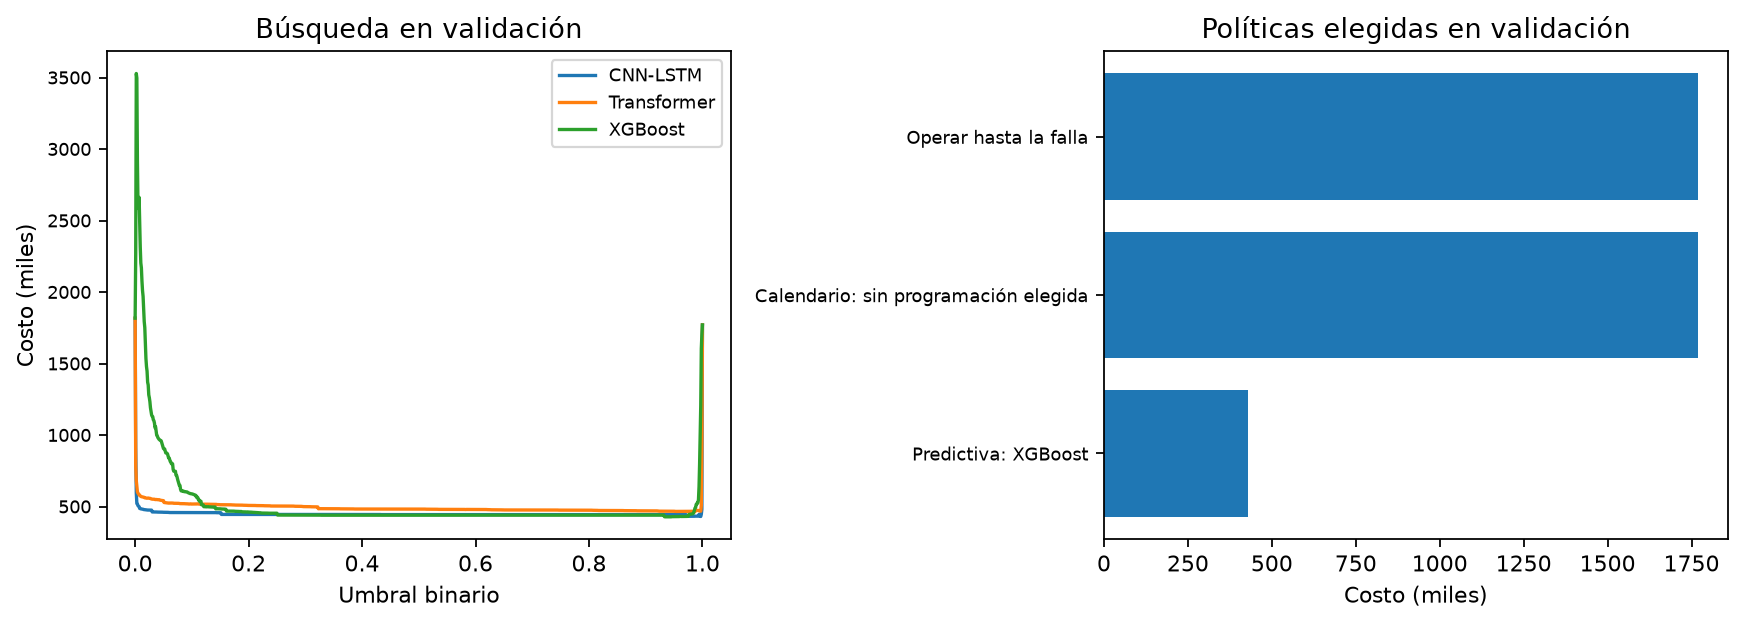

In [4]:
eventos_validacion_13 = fallas_periodo_13("2015-09-01", "2015-11-01")
evaluacion_validacion_13 = preparar_evaluacion_13(validacion_13, eventos_validacion_13)
umbrales_candidatos_13 = np.r_[np.arange(1001) / 1000, np.inf]
filas_busqueda_13 = []
acciones_validacion_13 = {}
for nombre, pred in predicciones_validacion_13.items():

    # Elegir componente no usa la falla futura; su correspondencia solo puntúa el resultado.
    propuestos = pred["multiclase"][:, 1:].argmax(axis=1)
    for umbral in umbrales_candidatos_13:
        filas = confirmar_13(pred["binaria"], umbral, evaluacion_validacion_13["continuidad"])
        conteos = contar_costos_13(filas, propuestos[filas], evaluacion_validacion_13, costos_13)
        filas_busqueda_13.append({"modelo": nombre, "umbral": umbral, **conteos})
busqueda_13 = pd.DataFrame(filas_busqueda_13)
mejores_por_modelo_13 = busqueda_13.sort_values(
    ["costo_total", "acciones", "umbral", "modelo"], ascending=[True, True, False, True]
    ).drop_duplicates("modelo").reset_index(drop=True)
elegido_13 = mejores_por_modelo_13.iloc[0]
display(mejores_por_modelo_13)

# Preparar una búsqueda separable por componente; no hay límite compartido de técnicos.
intervalos_13 = [24 * dias for dias in [7, 14, 30, 60, 90]] + [np.inf]
filas_calendario_13 = []
for numero, componente in enumerate(componentes_13):
    eventos_componente = eventos_validacion_13.loc[eventos_validacion_13.componente == componente]
    for intervalo in intervalos_13:
        filas = acciones_calendario_13(validacion_13, numero, intervalo)
        conteos = contar_costos_13(filas, np.full(len(filas), numero), evaluacion_validacion_13, costos_13)

        # Descontar fallas de otros componentes para elegir cada reloj de manera independiente.
        conteos["no_anticipadas"] = len(eventos_componente) - conteos["anticipadas"]
        conteos["costo_total"] = (3000 * conteos["anticipadas"] + 600 * conteos["sin_acierto_nuevo"]
                                  + 15000 * conteos["no_anticipadas"])
        conteos["costo_por_1000_h"] = conteos["costo_total"] / len(validacion_13) * 1000
        filas_calendario_13.append({"componente": componente, "intervalo_h": intervalo, **conteos})
busqueda_calendario_13 = pd.DataFrame(filas_calendario_13)
calendario_elegido_13 = busqueda_calendario_13.sort_values(
    ["costo_total", "acciones", "intervalo_h"], ascending=[True, True, False]
    ).drop_duplicates("componente").sort_values("componente").reset_index(drop=True)
display(calendario_elegido_13)


def puntuar_calendario_13(tabla, evaluacion, intervalos, costos):
    """Aplicar los cuatro intervalos ya elegidos sin volver a ajustarlos."""
    todas_filas, todos_componentes = [], []
    for numero, componente in enumerate(componentes_13):
        filas = acciones_calendario_13(tabla, numero, intervalos[componente])
        todas_filas.extend(filas.tolist())
        todos_componentes.extend([numero] * len(filas))
    return contar_costos_13(todas_filas, todos_componentes, evaluacion, costos)


intervalos_elegidos_13 = dict(zip(calendario_elegido_13.componente, calendario_elegido_13.intervalo_h))
calendario_val_13 = puntuar_calendario_13(validacion_13, evaluacion_validacion_13, intervalos_elegidos_13, costos_13)
reactivo_val_13 = contar_costos_13([], [], evaluacion_validacion_13, costos_13)
comparacion_val_13 = pd.DataFrame([
    {"politica": "Predictiva: " + elegido_13.modelo, **{k: elegido_13[k] for k in reactivo_val_13}},
    {"politica": "Calendario: sin programación elegida", **calendario_val_13},
    {"politica": "Operar hasta la falla", **reactivo_val_13}])
display(comparacion_val_13)
display(pd.DataFrame([{"periodo": "validación", **{k: evaluacion_validacion_13[k]
    for k in ["eventos", "horas", "fallas_con_borde"]}}]))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for nombre, grupo in busqueda_13.groupby("modelo"):
    finitas = grupo.loc[np.isfinite(grupo.umbral)]
    ejes[0].plot(finitas.umbral, finitas.costo_total / 1000, label=nombre)
ejes[0].set(xlabel="Umbral binario", ylabel="Costo (miles)", title="Búsqueda en validación")
ejes[0].legend(fontsize=8)
ejes[1].barh(comparacion_val_13.politica, comparacion_val_13.costo_total / 1000)
ejes[1].set(xlabel="Costo (miles)", title="Políticas elegidas en validación")
for eje in ejes:
    eje.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

### Qué eligió validación

XGBoost obtuvo el menor costo de la cuadrícula con **umbral 0.945**: 116 acciones, 112 fallas de componente anticipadas, cuatro acciones sin nuevo acierto y seis fallas no anticipadas. Su costo fue **428 400**, frente a 430 800 de CNN-LSTM y 464 400 del Transformer. La diferencia con CNN-LSTM es solo 2 400: corresponde a cuatro acciones adicionales sin nuevo acierto, con la misma cantidad de fallas anticipadas. No es una prueba de superioridad general ni estadística.

Este umbral económico sustituye para esta política al umbral de precisión horaria del 09. Son objetivos distintos; no se mezclan los resultados de ambos umbrales. El uso del Transformer en calibración e interpretabilidad sigue siendo un análisis de esa red, no una explicación o calibración de XGBoost.

Validación contiene **118 fallas de componente** y 144 000 horas-máquina disponibles. Seis fallas están cerca de bordes sin las 24 horas anteriores completas en esas anclas. Se conservan en el costo y no se ocultan las oportunidades incompletas.

Al permitir el intervalo infinito, el calendario eligió **no programar los cuatro componentes**. Por eso su costo, 1 770 000, coincide con operar hasta la falla. Es un resultado del criterio económico, pero no representa un programa activo de reemplazos. Más adelante mostramos también una referencia con intervalos finitos, para cumplir el contraste con un calendario que sí interviene.

## 5. Sensibilidad de costos antes de fijar la política

Variamos `costo de falla / costo de falsa alarma` entre **5, 10, 25, 50 y 100**. Se mantiene la falsa alarma en 600 y la intervención acertada en 3 000; el costo de falla cambia. La razón base es 25.

Recalculamos los costos de las decisiones candidatas ya generadas, sin volver a entrenar. Para cada escenario elegimos modelo/umbral y calendario usando exclusivamente validación. Esta tabla sirve para entender si la recomendación depende de los supuestos. **La prueba usará únicamente la razón base 25 y sus decisiones fijadas**, no el escenario que resulte más atractivo después.

,razon_falla_falsa,costo_falla,modelo,umbral,costo_predictiva,costo_calendario,costo_reactiva
0,5,3000,CNN-LSTM,inf,354000,354000,354000
1,10,6000,XGBoost,0.945,374400,708000,708000
2,25,15000,XGBoost,0.945,428400,1770000,1770000
3,50,30000,XGBoost,0.945,518400,3527400,3540000
4,100,60000,XGBoost,0.945,698400,7016400,7080000


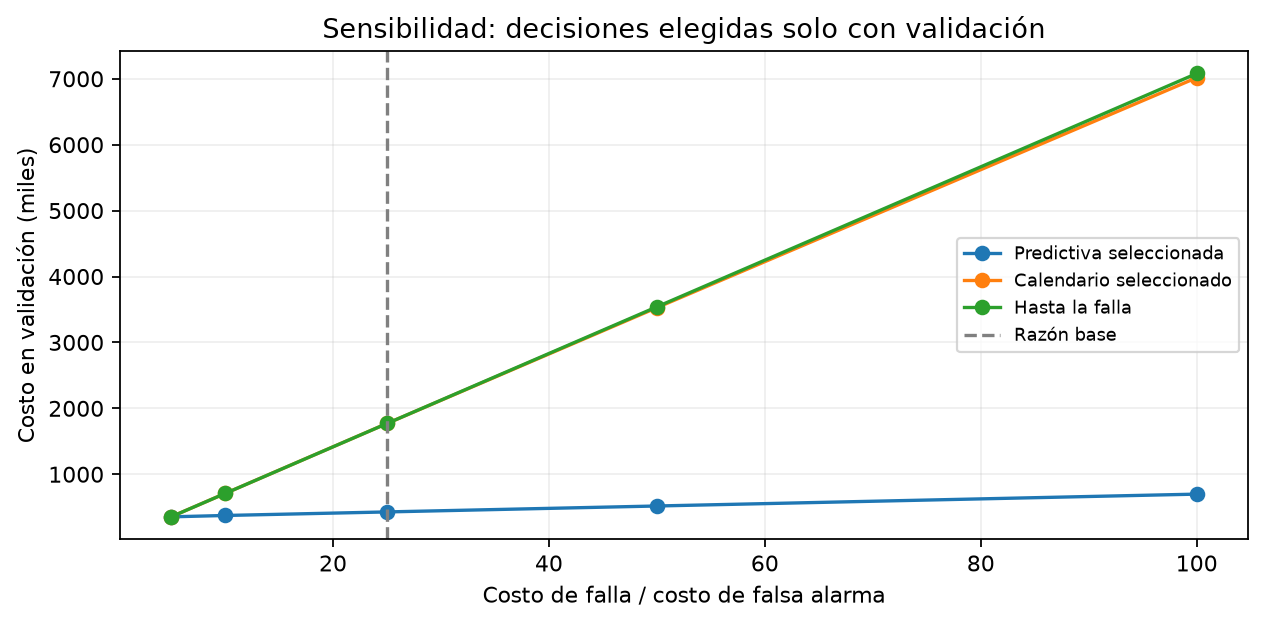

In [5]:
def recalcular_costo_13(tabla, costo_falla):
    """Cambiar precios manteniendo los conteos de acciones y fallas observados."""
    return (3000 * tabla["anticipadas"] + 600 * tabla["sin_acierto_nuevo"]
            + costo_falla * tabla["no_anticipadas"])


sensibilidad_13 = []
for razon in [5, 10, 25, 50, 100]:
    candidatos = busqueda_13.copy()
    candidatos["costo_escenario"] = recalcular_costo_13(candidatos, razon * 600)
    ganador = candidatos.sort_values(["costo_escenario", "acciones", "umbral", "modelo"],
        ascending=[True, True, False, True]).iloc[0]
    calendarios = busqueda_calendario_13.copy()
    calendarios["costo_escenario"] = recalcular_costo_13(calendarios, razon * 600)
    mejor_calendario = calendarios.sort_values(["costo_escenario", "acciones", "intervalo_h"],
        ascending=[True, True, False]).drop_duplicates("componente")
    sensibilidad_13.append({"razon_falla_falsa": razon, "costo_falla": razon * 600,
        "modelo": ganador.modelo, "umbral": ganador.umbral,
        "costo_predictiva": ganador.costo_escenario,
        "costo_calendario": mejor_calendario.costo_escenario.sum(),
        "costo_reactiva": evaluacion_validacion_13["eventos"] * razon * 600})
sensibilidad_13 = pd.DataFrame(sensibilidad_13)
display(sensibilidad_13)
fig, eje = plt.subplots(figsize=(8, 4))
for columna, nombre in [("costo_predictiva", "Predictiva seleccionada"),
                       ("costo_calendario", "Calendario seleccionado"), ("costo_reactiva", "Hasta la falla")]:
    eje.plot(sensibilidad_13.razon_falla_falsa, sensibilidad_13[columna] / 1000, marker="o", label=nombre)
eje.axvline(25, color="gray", linestyle="--", label="Razón base")
eje.set(xlabel="Costo de falla / costo de falsa alarma", ylabel="Costo en validación (miles)",
        title="Sensibilidad: decisiones elegidas solo con validación")
eje.legend(fontsize=8)
eje.grid(alpha=.2)
fig.tight_layout()
plt.show()

### Cómo cambia la recomendación con los costos

Cuando falla y acierto cuestan lo mismo (razón 5), no se obtiene beneficio por anticipar y las falsas alarmas solo agregan costo: la solución es **no alertar**. El nombre del modelo mostrado en ese empate no indica que CNN-LSTM sea mejor; sin acciones todos los modelos equivalen económicamente.

En las razones 10, 25, 50 y 100, la cuadrícula conserva **XGBoost y umbral 0.945**. Sus costos son respectivamente 374 400, 428 400, 518 400 y 698 400. Esto muestra estabilidad frente a esos precios concretos, no frente a cualquier supuesto posible. La falsa alarma se mantuvo en 600 y el acierto en 3 000: no variamos al mismo tiempo todas las cantidades.

El calendario con opción de no programar coincide con la política reactiva hasta la razón 25; para razones mayores alguna programación reduce ligeramente el costo de validación. La tabla usa únicamente validación. No se eligió un escenario mirando prueba.

## 6. Revisión visual de máquinas en validación

Esta revisión descriptiva se añadió después de fijar el protocolo final. **Usa únicamente septiembre–octubre de validación** y las probabilidades de XGBoost ya calculadas. No vuelve a entrenar, no consulta el CSV de prueba y no cambia modelo, umbral, calendario ni resultados finales. Se presenta aquí para facilitar la lectura, antes del acta y de prueba; este orden de presentación no cambia el momento en que se realizó ni significa que participara en la selección original.

Para evitar escoger solo gráficas favorables, seleccionamos la primera falla cronológica de cada componente que permita ver **72 horas anteriores y 48 posteriores** dentro de las anclas de validación. Pedimos máquinas distintas; los empates se resuelven por identificador de máquina. La selección usa fechas y componente, no probabilidades ni aciertos.

Los ejemplos están centrados en fallas y no representan todos los periodos sanos o todas las falsas alarmas. La revisión ayuda a buscar incoherencias temporales, pero no constituye otra evaluación independiente ni se utiliza para elegir decisiones nuevas.

Las celdas reutilizan las variables de validación de este notebook. Si ya no están en memoria, se pueden consultar directamente las salidas guardadas; esta sección no reconstruye modelos ni ejecuta la sección de prueba.

In [10]:
# Trabajar con copias de validación y con la selección ya calculada, sin modificar sus objetos.
requeridas_revision_13 = ["validacion_13", "predicciones_validacion_13", "eventos_validacion_13",
                         "evaluacion_validacion_13", "elegido_13"]
if not all(nombre in globals() for nombre in requeridas_revision_13):
    raise RuntimeError("Se necesitan las variables previas de validación. Las gráficas ya guardadas pueden consultarse sin ejecutar.")
modelo_revision_13 = str(elegido_13.modelo)
umbral_revision_13 = float(elegido_13.umbral)
revision_horas_13 = validacion_13[["machineID", "datetime"]].copy()
revision_horas_13["probabilidad"] = predicciones_validacion_13[modelo_revision_13]["binaria"].copy()
revision_horas_13["componente_propuesto"] = np.array(componentes_13)[
    predicciones_validacion_13[modelo_revision_13]["multiclase"][:, 1:].argmax(axis=1)]
assert revision_horas_13.datetime.between("2015-09-01", "2015-11-01", inclusive="left").all()

# Confirmar con la regla original sobre todo el periodo; no reiniciar la racha al recortar una figura.
filas_revision_13 = confirmar_13(revision_horas_13.probabilidad.to_numpy(), umbral_revision_13,
                                evaluacion_validacion_13["continuidad"])
confirmaciones_revision_13 = revision_horas_13.iloc[filas_revision_13].copy()

# Leer los eventos originales y conservar únicamente validación para esta revisión.
eventos_revision_13 = {}
for nombre, archivo in [("errores", "PdM_errors.csv"), ("mantenimiento", "PdM_maint.csv")]:
    tabla = pd.read_csv(ruta_repo / "Datos" / archivo, parse_dates=["datetime"])
    eventos_revision_13[nombre] = tabla.loc[
        tabla.datetime.between("2015-09-01", "2015-11-01", inclusive="left")].copy()
eventos_revision_13["fallas"] = eventos_validacion_13.copy()

# Elegir ejemplos por fechas y componente, sin consultar las probabilidades.
casos_revision_13 = []
maquinas_usadas_revision_13 = set()
for componente in componentes_13:
    candidatas = eventos_validacion_13.loc[eventos_validacion_13.componente == componente]
    candidatas = candidatas.sort_values(["datetime", "machineID"])
    for evento in candidatas.itertuples(index=False):
        if evento.machineID in maquinas_usadas_revision_13:
            continue
        inicio_ventana = evento.datetime - pd.Timedelta(hours=72)
        fin_ventana = evento.datetime + pd.Timedelta(hours=48)
        esperadas = pd.date_range(inicio_ventana, fin_ventana, freq="h")
        horas = pd.DatetimeIndex(revision_horas_13.loc[
            revision_horas_13.machineID == evento.machineID, "datetime"])
        if esperadas.isin(horas).all():
            casos_revision_13.append({"machineID": evento.machineID, "componente": componente,
                "falla_central": evento.datetime, "inicio": inicio_ventana, "fin": fin_ventana})
            maquinas_usadas_revision_13.add(evento.machineID)
            break
casos_revision_13 = pd.DataFrame(casos_revision_13)
assert len(casos_revision_13) == 4 and casos_revision_13.machineID.nunique() == 4
assert set(casos_revision_13.componente) == set(componentes_13)
display(casos_revision_13)

# Resumir la oportunidad de anticipar la falla central con el componente correcto.
resumen_revision_13 = []
for caso in casos_revision_13.itertuples(index=False):
    ventana = revision_horas_13.loc[(revision_horas_13.machineID == caso.machineID) &
        revision_horas_13.datetime.between(caso.inicio, caso.fin)]
    # Incluir el extremo de 24 horas, igual que el horizonte (t, t+24 h].
    confirmaciones = confirmaciones_revision_13.loc[
        (confirmaciones_revision_13.machineID == caso.machineID) &
        (confirmaciones_revision_13.datetime >= caso.falla_central - pd.Timedelta(hours=24)) &
        (confirmaciones_revision_13.datetime < caso.falla_central) &
        (confirmaciones_revision_13.componente_propuesto == caso.componente)]
    primera = confirmaciones.datetime.min() if len(confirmaciones) else pd.NaT
    anticipacion = (caso.falla_central - primera).total_seconds() / 3600 if pd.notna(primera) else np.nan
    fila = {"machineID": caso.machineID, "componente": caso.componente,
        "falla_central": caso.falla_central, "confirmacion_componente": primera,
        "anticipacion_h": anticipacion, "horas_mostradas": len(ventana)}
    for nombre, tabla in eventos_revision_13.items():
        seleccion = (tabla.machineID == caso.machineID) & tabla.datetime.between(caso.inicio, caso.fin)
        fila["registros_" + nombre] = int(seleccion.sum())
    mantenimiento = eventos_revision_13["mantenimiento"]
    fila["reemplazo_mismo_componente_y_hora"] = bool(((mantenimiento.machineID == caso.machineID) &
        (mantenimiento.comp == caso.componente) & (mantenimiento.datetime == caso.falla_central)).any())
    resumen_revision_13.append(fila)
resumen_revision_13 = pd.DataFrame(resumen_revision_13)
display(resumen_revision_13)

,machineID,componente,falla_central,inicio,fin
0,12,comp1,2015-09-04 06:00:00,2015-09-01 06:00:00,2015-09-06 06:00:00
1,36,comp2,2015-09-04 06:00:00,2015-09-01 06:00:00,2015-09-06 06:00:00
2,31,comp3,2015-09-04 06:00:00,2015-09-01 06:00:00,2015-09-06 06:00:00
3,75,comp4,2015-09-04 06:00:00,2015-09-01 06:00:00,2015-09-06 06:00:00


,machineID,componente,falla_central,confirmacion_componente,anticipacion_h,horas_mostradas,registros_errores,registros_mantenimiento,registros_fallas,reemplazo_mismo_componente_y_hora
0,12,comp1,2015-09-04 06:00:00,2015-09-03 08:00:00,22.0,121,2,1,1,True
1,36,comp2,2015-09-04 06:00:00,2015-09-03 08:00:00,22.0,121,2,2,1,True
2,31,comp3,2015-09-04 06:00:00,2015-09-03 08:00:00,22.0,121,1,1,1,True
3,75,comp4,2015-09-04 06:00:00,2015-09-03 08:00:00,22.0,121,2,1,1,True


### Cómo leer las líneas de tiempo

Cada figura comparte el mismo eje de fechas en cuatro paneles:

1. Probabilidad de cualquier falla en las siguientes 24 horas, umbral económico fijo y confirmaciones de tres horas. Los rombos muestran el componente propuesto; no significan por sí solos que la acción acertó.
2. Errores registrados por tipo. Cada marca es un registro, sin convertirlo en una falla.
3. Reemplazos registrados por componente. No se clasifican automáticamente como preventivos.
4. Fallas reales por componente. La línea roja discontinua señala la falla central elegida para el ejemplo.

El sombreado marca las 24 horas anteriores a la falla central como referencia descriptiva. Es información conocida al revisar los registros; **el modelo no recibió esa hora futura como entrada**. Un reemplazo en la misma hora de la falla puede ser consecuencia de ella: no demuestra información disponible antes del evento. El pipeline consulta reemplazos estrictamente anteriores a cada predicción.

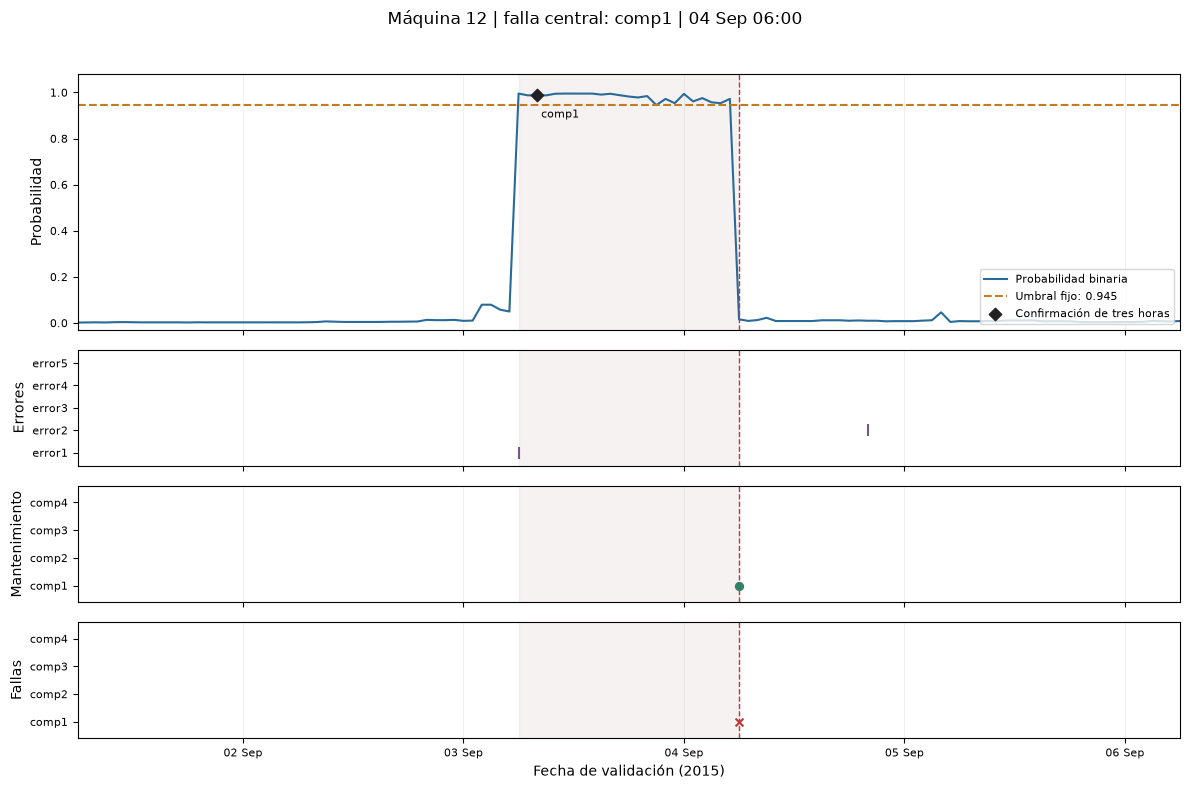

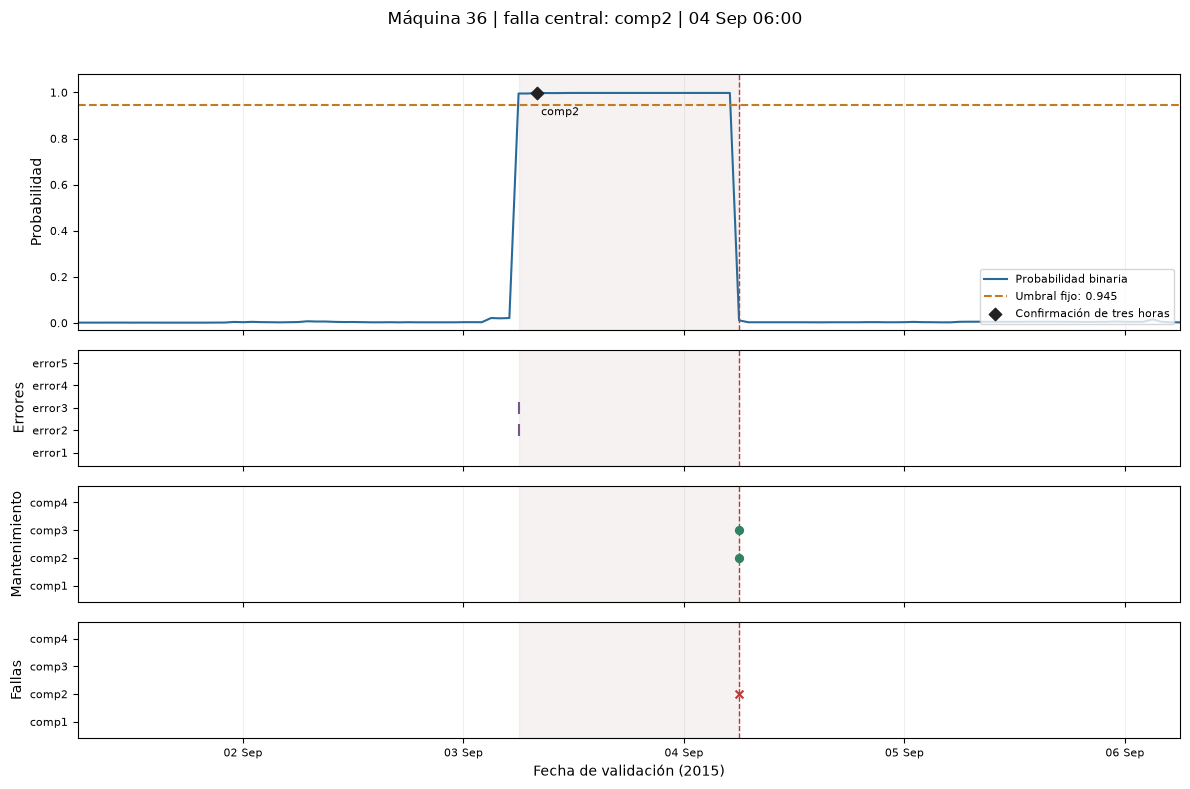

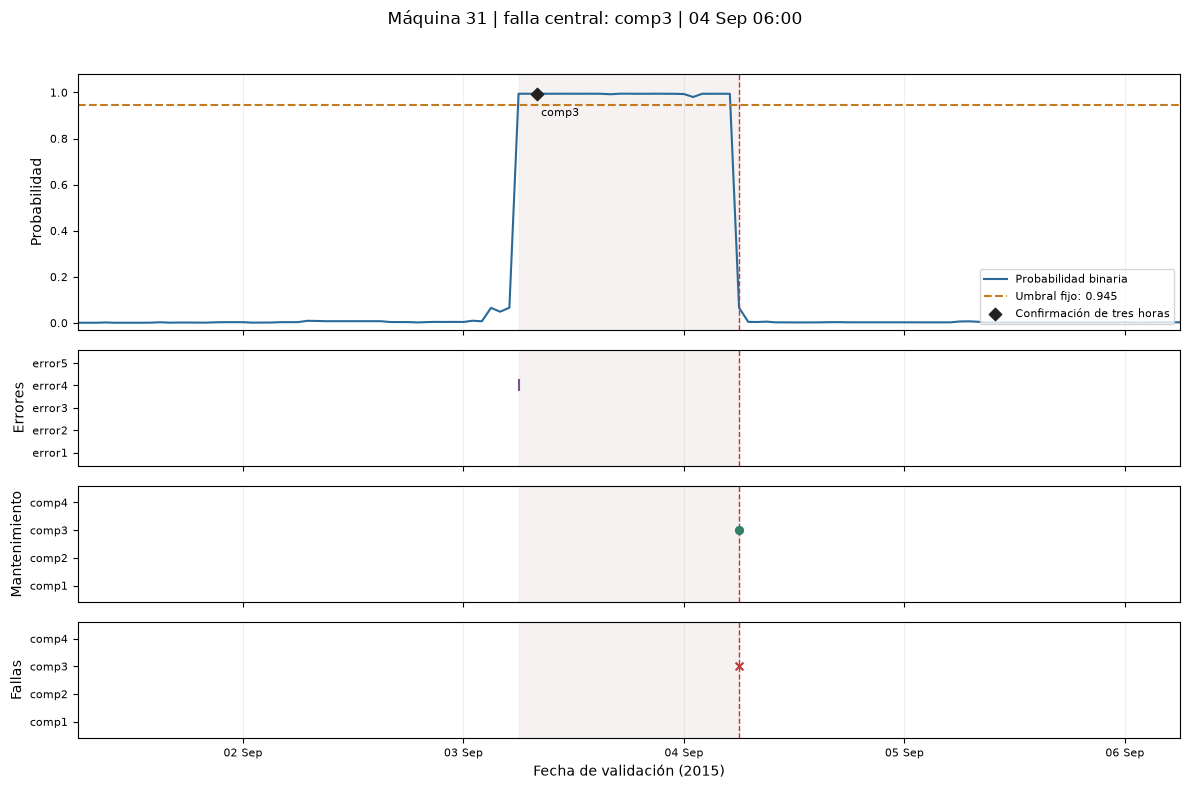

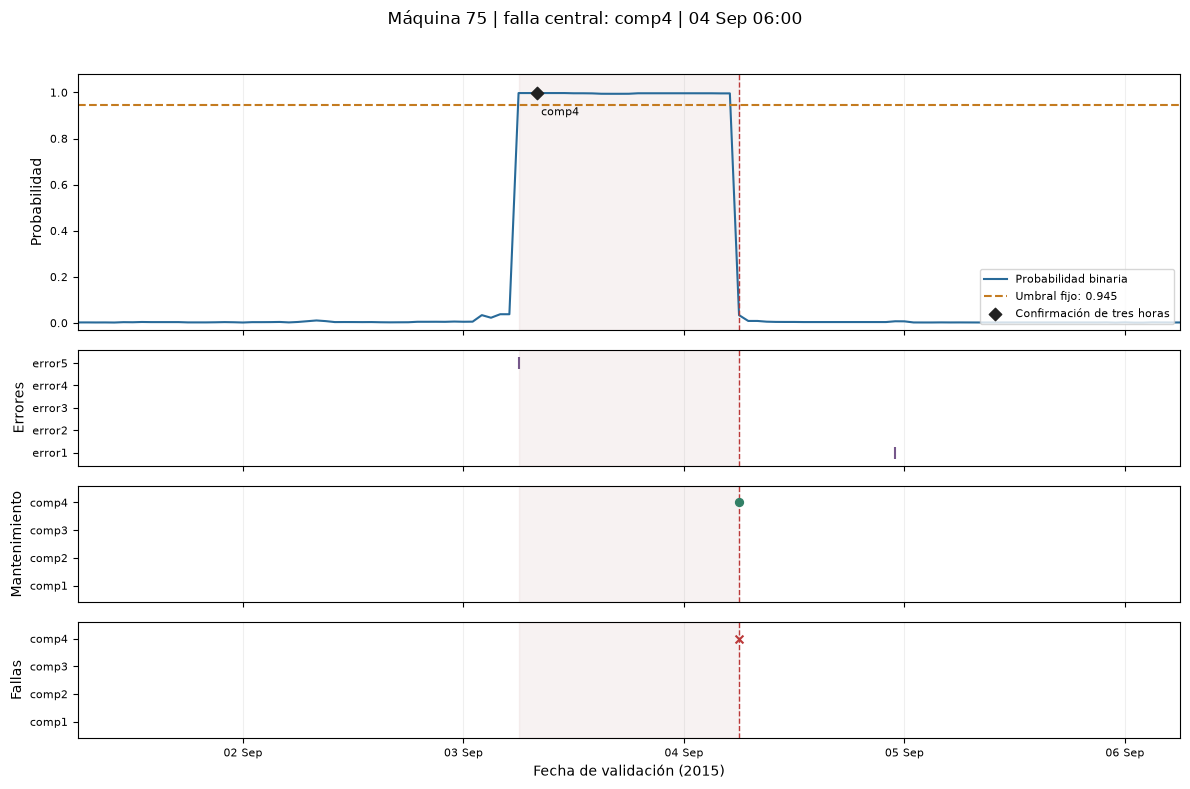

In [11]:
import matplotlib.dates as mdates

# Dibujar cuatro paneles con el mismo reloj para relacionar señales y eventos sin mezclarlos.
for caso in casos_revision_13.itertuples(index=False):
    horas = revision_horas_13.loc[(revision_horas_13.machineID == caso.machineID) &
        revision_horas_13.datetime.between(caso.inicio, caso.fin)]
    confirmaciones = confirmaciones_revision_13.loc[
        (confirmaciones_revision_13.machineID == caso.machineID) &
        confirmaciones_revision_13.datetime.between(caso.inicio, caso.fin)]
    fig, ejes = plt.subplots(4, 1, figsize=(12, 8), sharex=True,
                             gridspec_kw={"height_ratios": [2.2, 1, 1, 1]})
    ejes[0].plot(horas.datetime, horas.probabilidad, color="#286a99", label="Probabilidad binaria")
    ejes[0].axhline(umbral_revision_13, color="#c47b20", linestyle="--",
                   label="Umbral fijo: " + format(umbral_revision_13, ".3f"))
    if len(confirmaciones):
        ejes[0].scatter(confirmaciones.datetime, confirmaciones.probabilidad, marker="D", s=40,
                        color="#222222", label="Confirmación de tres horas", zorder=4)
        for alerta in confirmaciones.itertuples(index=False):
            ejes[0].annotate(alerta.componente_propuesto, (alerta.datetime, alerta.probabilidad),
                             xytext=(3, -16), textcoords="offset points", fontsize=8)
    ejes[0].set(ylabel="Probabilidad", ylim=(-.03, 1.08))
    ejes[0].legend(loc="lower right", fontsize=8)

    # Separar las categorías permite reconocer coincidencias de fecha sin confundir eventos.
    for numero_eje, nombre, columna, categorias, marcador, color in [
        (1, "errores", "errorID", ["error1", "error2", "error3", "error4", "error5"], "|", "#75578a"),
        (2, "mantenimiento", "comp", componentes_13, "o", "#328066"),
        (3, "fallas", "componente", componentes_13, "x", "#bb3939")]:
        tabla = eventos_revision_13[nombre]
        eventos = tabla.loc[(tabla.machineID == caso.machineID) & tabla.datetime.between(caso.inicio, caso.fin)]
        for posicion, categoria in enumerate(categorias):
            fechas = eventos.loc[eventos[columna] == categoria, "datetime"]
            ejes[numero_eje].scatter(fechas, np.full(len(fechas), posicion), marker=marcador,
                                    s=65 if marcador == "|" else 32, color=color, zorder=4)
        ejes[numero_eje].set(yticks=range(len(categorias)), yticklabels=categorias,
                             ylim=(-.6, len(categorias) - .4), ylabel=nombre.capitalize())
    for eje in ejes:
        eje.axvspan(caso.falla_central - pd.Timedelta(hours=24), caso.falla_central,
                    color="#d5b9b9", alpha=.18)
        eje.axvline(caso.falla_central, color="#bb3939", linestyle="--", linewidth=1)
        eje.grid(axis="x", alpha=.2)
        eje.tick_params(labelsize=8)
    ejes[-1].xaxis.set_major_locator(mdates.DayLocator())
    ejes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ejes[-1].set(xlim=(caso.inicio, caso.fin), xlabel="Fecha de validación (2015)")
    fig.suptitle("Máquina " + str(caso.machineID) + " | falla central: " + caso.componente +
                 " | " + caso.falla_central.strftime("%d %b %H:%M"), fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, .96))
    plt.show()

### Qué muestran estos cuatro ejemplos

La regla de selección eligió las máquinas **12, 36, 31 y 75**, correspondientes a comp1, comp2, comp3 y comp4. Las fallas centrales ocurrieron el **4 de septiembre de 2015 a las 06:00**. Cada figura contiene 121 mediciones horarias: desde 72 horas antes hasta 48 después, incluyendo ambos extremos.

En los cuatro casos se confirmó una alerta del componente correcto el **3 de septiembre a las 08:00**, con **22 horas de anticipación**. La confirmación se calculó sobre todo el periodo, no reiniciando la racha en el inicio de cada dibujo. Este resultado describe esos ejemplos elegidos por fecha; no reemplaza la cobertura ni los costos calculados con todos los casos.

- En la máquina 12 aparece error1 el día anterior a la falla de comp1; también aparece error2 después. No todo error visible anuncia la falla central ni debe reinterpretarse retrospectivamente como una señal acertada.
- En la máquina 36, error2 y error3 comparten hora antes de la falla de comp2. En la hora de esa falla hay reemplazos de comp2 y comp3, aunque solo se muestra una falla de comp2 en esta ventana. Un registro de mantenimiento no identifica por sí solo la causa ni equivale automáticamente a una falla de ese componente.
- En la máquina 31 aparece error4 antes de la falla de comp3 y en la 75 aparece error5 antes de la de comp4. Son coincidencias temporales observadas; esta figura no atribuye causalidad ni sustituye IG, que explicaba el Transformer y no XGBoost.

En los cuatro ejemplos hay un reemplazo del componente fallado **en la misma hora de su falla**. Puede ser una actuación correctiva, por lo que no lo interpretamos como información anticipada. El cálculo de horas desde reemplazo usa únicamente registros estrictamente anteriores a cada hora. La probabilidad representa una falla futura: una caída al llegar la falla no significa que el modelo la haya “borrado”, sino que cambia el horizonte que se predice.

No encontramos en estos ejemplos una discrepancia entre las horas de confirmación y la regla definida. Esto no demuestra ausencia de problemas en todas las máquinas. Son ventanas de datos simulados centradas en fallas, sin representar toda la diversidad de horas sanas o falsas alarmas.

**La revisión es descriptiva de validación. No motivó cambios de variables, pesos, modelo, umbral, calendario ni resultados de prueba. No se volvió a entrenar ni a realizar inferencia o evaluación de prueba para añadirla.**

## 7. Dejar las decisiones fijas antes de abrir prueba

El acta registra modelo, configuración original, umbral, calendario, costos y reglas. Su huella SHA-256 permite identificar las decisiones mostradas antes del primer acceso a prueba. Es una comprobación de contenido, no un sello externo de tiempo.

No se modifica el modelo con validación y no se prueban los candidatos descartados en prueba. El cálculo final usa solo noviembre–diciembre, con las mismas reglas de costos. Una vez vistos sus resultados, no se vuelve a elegir umbral, intervalo o modelo para esta entrega.

In [6]:
def numero_acta_13(valor):
    return None if np.isinf(valor) else float(valor)


acta_13 = {
    "modelo": str(elegido_13.modelo), "umbral": numero_acta_13(elegido_13.umbral),
    "configuracion": "05 XGBoost / 08 CNN-LSTM ponderada L24 / 10 Transformer, sin cambios",
    "costos": costos_13.copy(), "horizonte_h": 24, "horas_sostenidas": 3,
    "componente": "argmax de comp1-comp4 en confirmación", "acciones_por_racha": 1,
    "calendario_h": {k: numero_acta_13(v) for k, v in intervalos_elegidos_13.items()},
    "unidad": "falla de componente", "cuadricula": "0:0.001:1 y no alertar",
    "validacion": "2015-09-01 a 2015-11-01 excluido",
    "prueba": "2015-11-01 a 2016-01-01 excluido",
    "reajuste_con_validacion": False}
texto_acta_13 = json.dumps(acta_13, ensure_ascii=False, sort_keys=True)
huella_acta_13 = hashlib.sha256(texto_acta_13.encode()).hexdigest()
print(json.dumps(acta_13, ensure_ascii=False, indent=2))
print("Huella de decisiones:", huella_acta_13)
modelo_final_13 = str(elegido_13.modelo)
umbral_final_13 = float(elegido_13.umbral)
intervalos_finales_13 = copy.deepcopy(intervalos_elegidos_13)
costos_finales_13 = copy.deepcopy(costos_13)

# Conservar una copia de pesos para demostrar que la inferencia final no los cambia.
if modelo_final_13 != "XGBoost":
    red_final_13 = cnn_13["modelo"] if modelo_final_13 == "CNN-LSTM" else transformer_13["modelo"]
    pesos_antes_prueba_13 = {k: v.detach().clone() for k, v in red_final_13.state_dict().items()}
print("Decisiones fijadas. La siguiente sección abre prueba por primera vez en este procedimiento.")

{
  "modelo": "XGBoost",
  "umbral": 0.945,
  "configuracion": "05 XGBoost / 08 CNN-LSTM ponderada L24 / 10 Transformer, sin cambios",
  "costos": {
    "falla": 15000,
    "acierto": 3000,
    "falsa_alarma": 600
  },
  "horizonte_h": 24,
  "horas_sostenidas": 3,
  "componente": "argmax de comp1-comp4 en confirmación",
  "acciones_por_racha": 1,
  "calendario_h": {
    "comp1": null,
    "comp2": null,
    "comp3": null,
    "comp4": null
  },
  "unidad": "falla de componente",
  "cuadricula": "0:0.001:1 y no alertar",
  "validacion": "2015-09-01 a 2015-11-01 excluido",
  "prueba": "2015-11-01 a 2016-01-01 excluido",
  "reajuste_con_validacion": false
}
Huella de decisiones: bf4b019f898f4f06cab6f2bd7f1a6232bf7531ec4dd9f6a9194328b5ff218be8
Decisiones fijadas. La siguiente sección abre prueba por primera vez en este procedimiento.


## 8. Evaluación final en prueba

Esta celda no busca alternativas. Usa el modelo, umbral e intervalos del acta. En el mismo kernel, una segunda ejecución reutiliza el resultado final ya calculado y exige la misma huella; no genera otra selección.

Si gana una red, reconstruimos la historia hasta diciembre con las funciones del 06, aplicando **los imputadores, escaladores y vocabulario aprendidos en entrenamiento**, sin ajustarlos otra vez. Sus ventanas pueden incluir historia de octubre porque ya ocurrió antes de la hora a predecir. No usan mediciones futuras ni fallas como entradas. Si gana XGBoost, se aplican directamente sus pipelines ajustados a los CSV preparados.

Guardar este notebook conserva las salidas, no los objetos en memoria. En un kernel nuevo, ejecutarlo completo reproduce el protocolo fijado, pero no debe utilizarse para iniciar cambios basados en prueba. Para consultar la evaluación ya realizada basta leer estas salidas.

,politica,acciones,anticipadas,sin_acierto_nuevo,no_anticipadas,costo_total,costo_por_1000_h
0,Predictiva: XGBoost,124,114,10,7,453000,3145.833333
1,Calendario: sin programación elegida,0,0,0,121,1815000,12604.166667
2,Operar hasta la falla,0,0,0,121,1815000,12604.166667


,periodo,eventos,horas,fallas_con_borde
0,prueba,121,144000,8


Ahorro retrospectivo frente a operar hasta la falla: 1362000


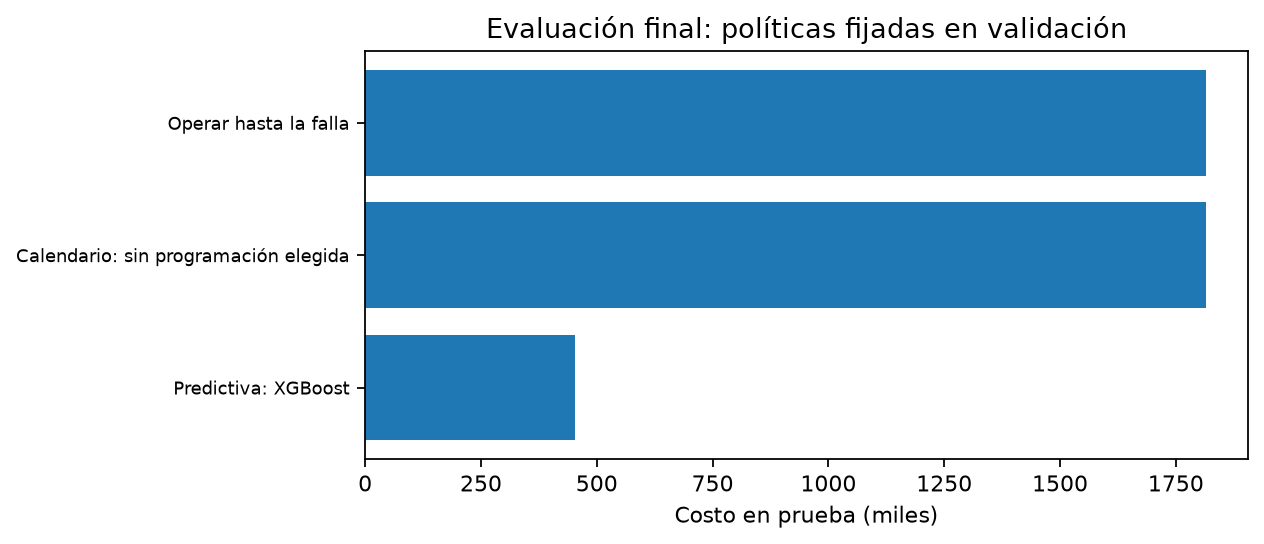

In [7]:
def predecir_red_prueba_13(tabla):
    """Aplicar una red ya elegida sin ajustar ningún parámetro con prueba."""
    from preparar_secuencias import (construir_historia, crear_series, localizar_anclas,
        VentanasMaquina, continuos)
    datos = {}
    for nombre, archivo in [("telemetria", "PdM_telemetry.csv"), ("errores", "PdM_errors.csv"),
                            ("mantenimiento", "PdM_maint.csv")]:
        fuente = pd.read_csv(ruta_repo / "Datos" / archivo, parse_dates=["datetime"])
        seleccion = fuente.datetime < pd.Timestamp("2016-01-01")
        if nombre != "mantenimiento":
            seleccion &= fuente.datetime >= pd.Timestamp("2015-01-01")
        datos[nombre] = fuente.loc[seleccion].copy()
    maquinas = pd.read_csv(ruta_repo / "Datos/PdM_machines.csv")
    historia = construir_historia(datos, maquinas)
    historia[continuos] = preparacion_13["escalador"].transform(
        preparacion_13["imputador"].transform(historia[continuos]))

    # Usar el vocabulario y el escalador de edad ya ajustados; no llamar a fit.
    catalogo = maquinas.copy()
    catalogo["modelo_codigo"] = catalogo.model.map(preparacion_13["mapa_modelos"]).fillna(0).astype(int)
    catalogo["edad_normalizada"] = preparacion_13["escalador_edad"].transform(catalogo[["age"]]).ravel()
    series = crear_series(historia, catalogo.set_index("machineID"))
    anclas = localizar_anclas(tabla[claves_13 + ["etiqueta_binaria", "etiqueta_multiclase"]], 24, series)
    pd.testing.assert_frame_equal(anclas[claves_13].reset_index(drop=True), tabla[claves_13])
    dataset = VentanasMaquina(anclas, 24, series)
    binarias, multiclasificadas = [], []
    red_final_13.eval()
    with torch.no_grad():
        for lote in DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0):
            salida = red_final_13(lote["dinamicas"], lote["modelo"], lote["edad"])
            binarias.append(torch.sigmoid(salida["binaria"]).numpy().ravel())
            multiclasificadas.append(torch.softmax(salida["multiclase"], dim=1).numpy())
    assert all(torch.equal(v, pesos_antes_prueba_13[k]) for k, v in red_final_13.state_dict().items())
    return {"binaria": np.concatenate(binarias), "multiclase": np.concatenate(multiclasificadas)}


if "resultado_final_13" in globals():
    assert resultado_final_13["huella"] == huella_acta_13, "No cambiar decisiones después de examinar prueba."
    print("Se conserva la evaluación final ya calculada en este kernel.")
else:
    assert hashlib.sha256(json.dumps(acta_13, ensure_ascii=False, sort_keys=True).encode()).hexdigest() == huella_acta_13
    prueba_13 = pd.read_csv(ruta_repo / "Datos/Datos_preparados/prueba.csv", parse_dates=["datetime"])
    prueba_13 = prueba_13.sort_values(claves_13).reset_index(drop=True)
    assert len(prueba_13) == 144000
    assert prueba_13.datetime.between("2015-11-01", "2016-01-01", inclusive="left").all()
    assert (prueba_13.datetime + pd.Timedelta(hours=24) < pd.Timestamp("2016-01-01")).all()
    assert not prueba_13.duplicated(claves_13).any()
    if modelo_final_13 == "XGBoost":
        prediccion_prueba_13 = ejecutar_xgb_13("prueba")
        assert np.array_equal(prediccion_prueba_13["ids"], prueba_13.machineID)
        assert np.array_equal(prediccion_prueba_13["horas"], prueba_13.datetime.to_numpy())
    else:
        prediccion_prueba_13 = predecir_red_prueba_13(prueba_13)
    eventos_prueba_13 = fallas_periodo_13("2015-11-01", "2016-01-01")
    evaluacion_prueba_13 = preparar_evaluacion_13(prueba_13, eventos_prueba_13)
    filas_prueba_13 = confirmar_13(prediccion_prueba_13["binaria"], umbral_final_13,
                                  evaluacion_prueba_13["continuidad"])
    componentes_prueba_13 = prediccion_prueba_13["multiclase"][:, 1:].argmax(axis=1)
    predictiva_prueba_13 = contar_costos_13(filas_prueba_13, componentes_prueba_13[filas_prueba_13],
                                          evaluacion_prueba_13, costos_finales_13)
    calendario_prueba_13 = puntuar_calendario_13(prueba_13, evaluacion_prueba_13,
                                               intervalos_finales_13, costos_finales_13)
    reactiva_prueba_13 = contar_costos_13([], [], evaluacion_prueba_13, costos_finales_13)
    resultado_final_13 = {"huella": huella_acta_13, "predictiva": predictiva_prueba_13,
        "calendario": calendario_prueba_13, "reactiva": reactiva_prueba_13}

comparacion_prueba_13 = pd.DataFrame([
    {"politica": "Predictiva: " + modelo_final_13, **resultado_final_13["predictiva"]},
    {"politica": "Calendario: sin programación elegida", **resultado_final_13["calendario"]},
    {"politica": "Operar hasta la falla", **resultado_final_13["reactiva"]}])
display(comparacion_prueba_13)
display(pd.DataFrame([{"periodo": "prueba", **{k: evaluacion_prueba_13[k]
    for k in ["eventos", "horas", "fallas_con_borde"]}}]))
print("Ahorro retrospectivo frente a operar hasta la falla:",
    resultado_final_13["reactiva"]["costo_total"] - resultado_final_13["predictiva"]["costo_total"])

fig, eje = plt.subplots(figsize=(8, 3.5))
eje.barh(comparacion_prueba_13.politica, comparacion_prueba_13.costo_total / 1000)
eje.set(xlabel="Costo en prueba (miles)", title="Evaluación final: políticas fijadas en validación")
eje.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

# Eliminar el intercambio temporal de XGBoost; las salidas quedan dentro del notebook.
temporal_xgb_13.cleanup()

### Resultado de la política predictiva fijada

Con **XGBoost y umbral 0.945**, prueba produjo **124 acciones**: 114 acreditadas a fallas diferentes y diez sin nuevo acierto. Quedaron siete fallas no anticipadas, de **121 fallas de componente**. El costo fue **453 000**:

`114 × 3 000 + 10 × 600 + 7 × 15 000 = 453 000`.

Operar hasta la falla cuesta **1 815 000**. La diferencia retrospectiva es **1 362 000**, aproximadamente **75.04 %**, bajo los costos y reglas asumidos. La cobertura de fallas de componente es 114/121, aproximadamente 94.21 %. No son fallas que se haya demostrado evitar en una intervención real.

Hay ocho fallas cercanas a bordes sin las 24 horas anteriores completas en las anclas; no se retiraron del denominador. No se hicieron predicciones de CNN-LSTM ni Transformer sobre prueba para intentar mejorar el resultado. El calendario con opción de no programar permaneció sin acciones y coincidió con la política reactiva.

## 9. Referencia adicional: calendario que sí programa reemplazos

La primera búsqueda permitía no intervenir; validación eligió esa opción. Durante la revisión, **después de la primera inferencia final**, se completó además esta referencia operativa para no presentar como calendario activo lo que era ausencia de programación.

Se selecciona para cada componente el mejor **intervalo finito** entre los mismos 7, 14, 30, 60 y 90 días ya evaluados en validación. No se genera otra búsqueda ni se usan costos de prueba para elegirlos. La referencia se puntúa una vez con los eventos de prueba ya cargados. **No se repite la inferencia ni cambia XGBoost, su umbral o sus acciones**, que corresponden al acta original.

Esta aclaración registra la secuencia real del trabajo: el acta original contenía la opción sin programación y esta comparación activa se añadió en revisión. Sus resultados deben leerse como referencia retrospectiva, no como una segunda selección del modelo final.

,componente,intervalo_h,acciones,anticipadas,costo_total
0,comp1,2160.0,27,0,331200
1,comp2,2160.0,28,0,706800
2,comp3,2160.0,28,0,316800
3,comp4,2160.0,25,1,467400


,periodo,acciones,anticipadas,sin_acierto_nuevo,no_anticipadas,costo_total,costo_por_1000_h
0,validación,108,1,107,117,1822200,12654.166667
1,prueba,137,1,136,120,1884600,13087.500000


,politica,acciones,anticipadas,sin_acierto_nuevo,no_anticipadas,costo_total,costo_por_1000_h
0,Predictiva: XGBoost,124,114,10,7,453000,3145.833333
1,Calendario activo por componente,137,1,136,120,1884600,13087.500000
2,Operar hasta la falla,0,0,0,121,1815000,12604.166667


,razon_falla_falsa,costo_calendario_activo
0,5,418200
1,10,769200
2,25,1822200
3,50,3569400
4,100,7049400


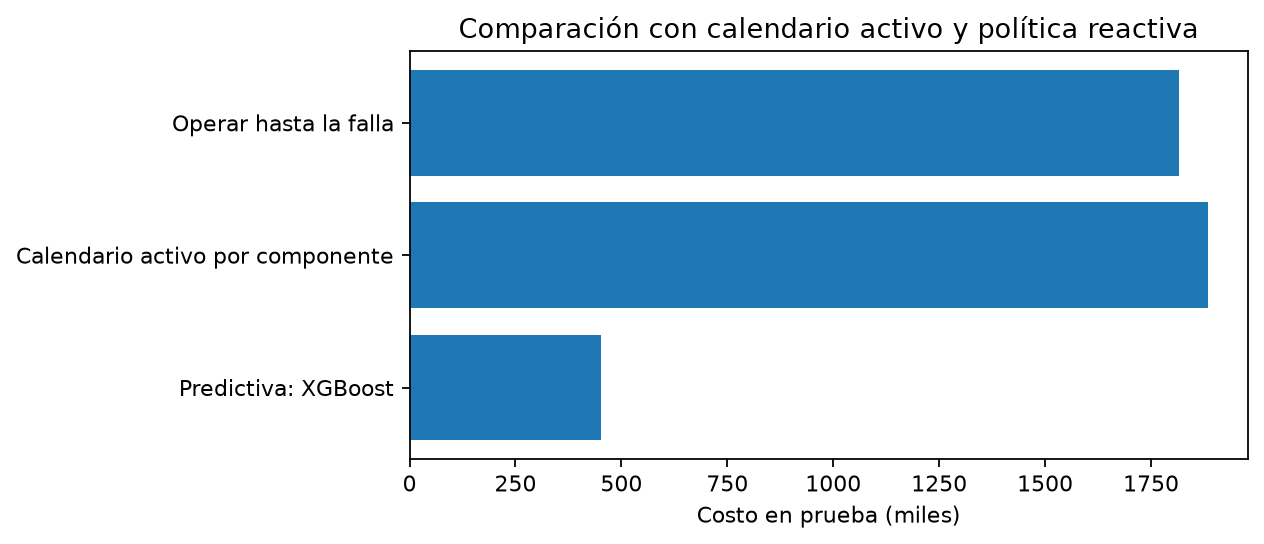

In [8]:
# Elegir únicamente a partir de los candidatos de validación ya calculados.
calendarios_finitos_13 = busqueda_calendario_13.loc[np.isfinite(busqueda_calendario_13.intervalo_h)].copy()
calendario_activo_13 = calendarios_finitos_13.sort_values(
    ["costo_total", "acciones", "intervalo_h"], ascending=[True, True, False]
    ).drop_duplicates("componente").sort_values("componente").reset_index(drop=True)
intervalos_activos_13 = dict(zip(calendario_activo_13.componente, calendario_activo_13.intervalo_h))
display(calendario_activo_13[["componente", "intervalo_h", "acciones", "anticipadas", "costo_total"]])

# Aplicar esos intervalos sin revisar candidatos alternativos en prueba ni volver a predecir.
calendario_activo_val_13 = puntuar_calendario_13(validacion_13, evaluacion_validacion_13,
                                               intervalos_activos_13, costos_finales_13)
calendario_activo_prueba_13 = puntuar_calendario_13(prueba_13, evaluacion_prueba_13,
                                                  intervalos_activos_13, costos_finales_13)
comparacion_principal_final_13 = pd.DataFrame([
    {"politica": "Predictiva: " + modelo_final_13, **resultado_final_13["predictiva"]},
    {"politica": "Calendario activo por componente", **calendario_activo_prueba_13},
    {"politica": "Operar hasta la falla", **resultado_final_13["reactiva"]}])
display(pd.DataFrame([{"periodo": "validación", **calendario_activo_val_13},
                      {"periodo": "prueba", **calendario_activo_prueba_13}]))
display(comparacion_principal_final_13)

# Completar la sensibilidad de esta referencia activa usando solo validación.
sensibilidad_calendario_activo_13 = []
for razon in [5, 10, 25, 50, 100]:
    candidatos = calendarios_finitos_13.copy()
    candidatos["costo_escenario"] = recalcular_costo_13(candidatos, razon * 600)
    elegidos = candidatos.sort_values(["costo_escenario", "acciones", "intervalo_h"],
        ascending=[True, True, False]).drop_duplicates("componente")
    sensibilidad_calendario_activo_13.append({"razon_falla_falsa": razon,
                                             "costo_calendario_activo": elegidos.costo_escenario.sum()})
sensibilidad_calendario_activo_13 = pd.DataFrame(sensibilidad_calendario_activo_13)
display(sensibilidad_calendario_activo_13)
fig, eje = plt.subplots(figsize=(8, 3.5))
eje.barh(comparacion_principal_final_13.politica, comparacion_principal_final_13.costo_total / 1000)
eje.set(xlabel="Costo en prueba (miles)", title="Comparación con calendario activo y política reactiva")
fig.tight_layout()
plt.show()

### Lectura del calendario activo

Los cuatro componentes seleccionan **90 días (2 160 horas)** entre los intervalos finitos explorados. En validación, ese calendario costó **1 822 200**: 108 acciones, una falla anticipada y 117 no anticipadas. En prueba costó **1 884 600**: 137 acciones, una falla anticipada, 136 acciones sin nuevo acierto y 120 fallas no anticipadas.

El calendario activo resulta más caro que operar hasta la falla bajo esta tabla. Esto explica que el optimizador inicial prefiriera no programar. No demuestra que todo mantenimiento por calendario sea inútil: influyen los intervalos probados, la trayectoria histórica, el reloj definido y el supuesto de 600 para una acción sin falla próxima. El calendario no puede aprovechar el conocimiento futuro de cuándo fallará un componente.

La tabla principal compara ahora una política predictiva, un calendario con acciones y la referencia reactiva. El resultado predictivo permanece exactamente igual al evaluado con el acta original.

## 10. Métricas del mismo modelo final, sin seleccionar otro umbral

El costo se evaluó por acciones y fallas de componente. Estas métricas adicionales son **por hora**: no sustituyen el costo ni la precisión por episodio. Conservamos el umbral económico incluso si la precisión horaria final no llega a 0.80. No elegimos un umbral nuevo mirando prueba.

La matriz multiclase usa el argmax de las cinco clases, como en las etapas anteriores; para la acción de mantenimiento, en cambio, se propone el componente entre los cuatro cuando la cabeza binaria confirma una alerta. Las dos reglas tienen propósitos distintos y se registraron antes de abrir prueba.

,modelo,AP_PR_AUC,ROC_AUC,Brier_binario,precision_umbral_fijado,recall_umbral_fijado,F1_macro_5,F1_macro_componentes
0,XGBoost,0.998404,0.999973,0.000623,0.989069,0.987208,0.990085,0.987655


,componente,F1
0,comp1,0.979592
1,comp2,1.000000
2,comp3,0.976744
3,comp4,0.994286


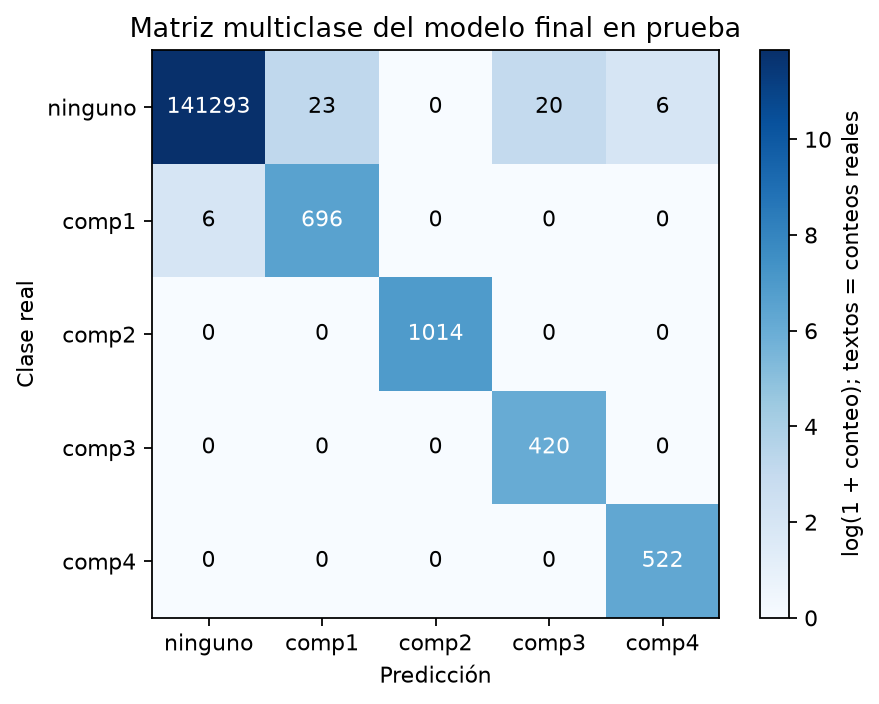

In [9]:
y_bin_prueba_13 = prueba_13.etiqueta_binaria.to_numpy(dtype=int)
y_multi_prueba_13 = prueba_13.etiqueta_multiclase.map(dict(zip(clases_13, range(5)))).to_numpy()
p_bin_prueba_13 = prediccion_prueba_13["binaria"]
p_multi_prueba_13 = prediccion_prueba_13["multiclase"]
assert np.isfinite(p_bin_prueba_13).all() and np.isfinite(p_multi_prueba_13).all()
assert np.allclose(p_multi_prueba_13.sum(axis=1), 1, atol=1e-5)
clase_prueba_13 = p_multi_prueba_13.argmax(axis=1)
metricas_finales_13 = pd.DataFrame([{
    "modelo": modelo_final_13, "AP_PR_AUC": average_precision_score(y_bin_prueba_13, p_bin_prueba_13),
    "ROC_AUC": roc_auc_score(y_bin_prueba_13, p_bin_prueba_13),
    "Brier_binario": brier_score_loss(y_bin_prueba_13, p_bin_prueba_13),
    "precision_umbral_fijado": precision_score(y_bin_prueba_13, p_bin_prueba_13 >= umbral_final_13, zero_division=0),
    "recall_umbral_fijado": recall_score(y_bin_prueba_13, p_bin_prueba_13 >= umbral_final_13, zero_division=0),
    "F1_macro_5": f1_score(y_multi_prueba_13, clase_prueba_13, labels=range(5), average="macro", zero_division=0),
    "F1_macro_componentes": f1_score(y_multi_prueba_13, clase_prueba_13, labels=range(1, 5), average="macro", zero_division=0)}])
display(metricas_finales_13)
display(pd.DataFrame({"componente": componentes_13,
    "F1": f1_score(y_multi_prueba_13, clase_prueba_13, labels=range(1, 5), average=None, zero_division=0)}))
matriz_final_13 = confusion_matrix(y_multi_prueba_13, clase_prueba_13, labels=range(5))
fig, eje = plt.subplots(figsize=(6, 4.5))
imagen = eje.imshow(np.log1p(matriz_final_13), cmap="Blues")
for fila in range(5):
    for columna in range(5):
        eje.text(columna, fila, str(matriz_final_13[fila, columna]), ha="center", va="center",
                 color="white" if np.log1p(matriz_final_13[fila, columna]) > np.log1p(matriz_final_13).max() / 2 else "black")
eje.set(xticks=range(5), yticks=range(5), xticklabels=clases_13, yticklabels=clases_13,
        xlabel="Predicción", ylabel="Clase real", title="Matriz multiclase del modelo final en prueba")
fig.colorbar(imagen, ax=eje, label="log(1 + conteo); textos = conteos reales")
fig.tight_layout()
plt.show()

### Lectura de las métricas finales y límites

En las mismas predicciones finales, XGBoost obtuvo **AP 0.998404**, **ROC-AUC 0.999973**, Brier binario **0.000623**, F1 macro de cinco clases **0.990085** y F1 macro de los cuatro componentes **0.987655**. Con el umbral económico ya fijado, la precisión horaria fue **0.989069** y el recall **0.987208**. No se ajustó otro umbral con prueba.

Los F1 de comp1–comp4 fueron aproximadamente **0.97959, 1.00000, 0.97674 y 0.99429**. La matriz muestra conteos reales; solo su color usa `log(1 + conteo)` para poder ver las clases pequeñas. El predominio de horas sin falla y los datos simulados limitan la generalización a otra planta.

La precisión por acción de la política es 114/124 (91.94 %) y su cobertura por falla de componente es 114/121 (94.21 %); son cantidades distintas de la precisión y recall horarios anteriores. No debe interpretarse una métrica por hora como si describiera automáticamente episodios de mantenimiento.

Este paso deja el modelo y su política económica elegidos, las referencias comparadas y una evaluación final de prueba. No se modificó el modelo ni el umbral predictivo después de ver sus resultados; la referencia de calendario activo añadida en revisión quedó identificada en la sección 9. Las conclusiones dependen de la tabla de costos, la regla de acción, las fronteras y el supuesto de conservar la trayectoria histórica después de las intervenciones virtuales. 